# Member 4 — Regression Modeling & User Segmentation
**Project:** Social Media and Stress Patterns — Fundamentals of Data Analytics  
**Dataset:** `data/processed/social_media_stress_clean.csv`  
**Objectives:** predict stress using user habits, compare models, tune a random forest, identify important predictors, optionally predict happiness, and segment users.

**How to run:** Open this notebook in Jupyter, choose **Kernel → Restart & Run All**. The notebook works when Jupyter opens at the project root **or** inside its `notebooks` folder. No need to run cells separately.

## 1. Imports and project paths

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, silhouette_score
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans

# Find the project root whether Jupyter starts in project/ or project/notebooks/.
current = Path.cwd().resolve()
candidates = [current, current.parent]
roots = [p for p in candidates if (p / 'data/processed/social_media_stress_clean.csv').exists()]
if not roots:
    raise FileNotFoundError(
        'Could not locate data/processed/social_media_stress_clean.csv. '
        'Open Jupyter from the social-media-stress-analysis project folder or its notebooks folder.'
    )
PROJECT_ROOT = roots[0]
DATA_FILE = PROJECT_ROOT / 'data/processed/social_media_stress_clean.csv'
REPORT_DIR = PROJECT_ROOT / 'reports'
FIG_DIR = REPORT_DIR / 'figures'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Project folder:', PROJECT_ROOT)
print('Dataset:', DATA_FILE)
print('Outputs:', REPORT_DIR)

Project folder: C:\Users\Owner\Downloads\social-media-stress-analysis-main\social-media-stress-analysis-main
Dataset: C:\Users\Owner\Downloads\social-media-stress-analysis-main\social-media-stress-analysis-main\data\processed\social_media_stress_clean.csv
Outputs: C:\Users\Owner\Downloads\social-media-stress-analysis-main\social-media-stress-analysis-main\reports


## 2. Load and inspect cleaned data

In [5]:
df = pd.read_csv(DATA_FILE)
print('Dataset shape:', df.shape)
print('Missing cells:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
display(df.head())
display(df.describe(include='all').T)

Dataset shape: (500, 11)
Missing cells: 0
Duplicate rows: 0


,user_id,age,gender,daily_screen_time_hours,sleep_quality,stress_level,days_without_social_media,exercise_frequency_per_week,social_media_platform,happiness_index,screen_time_group
0,U001,44,Male,3.1,7,6,2,5,Facebook,10,3-6 hrs
1,U002,30,Other,5.1,7,8,5,3,LinkedIn,10,3-6 hrs
2,U003,23,Other,7.4,6,7,1,3,YouTube,6,6-9 hrs
3,U004,36,Female,5.7,7,8,1,1,TikTok,8,3-6 hrs
4,U005,34,Female,7.0,4,7,5,1,X (Twitter),8,6-9 hrs


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,500,500,U001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,500.0,NaN,NaN,NaN,32.988,9.960637,16.0,24.0,34.0,41.0,49.0
gender,500,3,Male,248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
daily_screen_time_hours,500.0,NaN,NaN,NaN,5.53,1.734877,1.0,4.3,5.6,6.7,10.8
sleep_quality,500.0,NaN,NaN,NaN,6.304,1.529792,2.0,5.0,6.0,7.0,10.0
stress_level,500.0,NaN,NaN,NaN,6.618,1.542996,2.0,6.0,7.0,8.0,10.0
days_without_social_media,500.0,NaN,NaN,NaN,3.134,1.858751,0.0,2.0,3.0,5.0,9.0
exercise_frequency_per_week,500.0,NaN,NaN,NaN,2.448,1.428067,0.0,1.0,2.0,3.0,7.0
social_media_platform,500,6,TikTok,95,NaN,NaN,NaN,NaN,NaN,NaN,NaN
happiness_index,500.0,NaN,NaN,NaN,8.376,1.524228,4.0,7.0,9.0,10.0,10.0


## 3. Predictors and target
Target: `stress_level` (numerical). Predictors: age, gender, daily screen time, sleep quality, days without social media, exercise frequency, social media platform. We exclude `user_id` (identifier), `screen_time_group` (derived from daily screen time), and `happiness_index` (another wellbeing outcome, not a behavioral predictor; excluding it avoids making stress prediction depend on a closely related outcome). This is an association/prediction study, not causal proof.

In [6]:
numeric_features = [
    'age', 'daily_screen_time_hours', 'sleep_quality',
    'days_without_social_media', 'exercise_frequency_per_week'
]
categorical_features = ['gender', 'social_media_platform']
features = numeric_features + categorical_features
X = df[features].copy()
y = df['stress_level'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))

def preprocessing():
    return ColumnTransformer([
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_features),
    ])

def linear_model():
    return Pipeline([('prep', preprocessing()), ('model', LinearRegression())])

def forest_model():
    return Pipeline([('prep', preprocessing()),
                     ('model', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))])

def scores(truth, predicted):
    return {'RMSE': float(np.sqrt(mean_squared_error(truth, predicted))),
            'R2': float(r2_score(truth, predicted))}


Training rows: 400 | Test rows: 100


## 4. Train and compare Linear Regression and Random Forest on the 20% test set

In [7]:
linear = linear_model()
forest = forest_model()
linear.fit(X_train, y_train)
forest.fit(X_train, y_train)
linear_pred = linear.predict(X_test)
forest_pred = forest.predict(X_test)
results = {
    'Linear Regression': scores(y_test, linear_pred),
    'Random Forest': scores(y_test, forest_pred),
}
comparison = pd.DataFrame.from_dict(results, orient='index')
comparison.index.name = 'Model'
display(comparison.round(4))
print('Lower RMSE = better; higher R² = better.')

,RMSE,R2
Model,,
Linear Regression,1.0572,0.536
Random Forest,1.0874,0.509


Lower RMSE = better; higher R² = better.


## 5. Five-fold cross-validation
Cross-validation runs **only on the 80% training split**, preserving the test set as an independent final evaluation. We use shuffled KFold with `random_state=42`.

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in [('Linear Regression', linear_model()), ('Random Forest', forest_model())]:
    rmse_folds = -cross_val_score(
        model, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=1
    )
    cv_rows.append({'Model': name, 'CV mean RMSE': rmse_folds.mean(),
                    'CV std RMSE': rmse_folds.std(), 'Fold RMSEs': np.round(rmse_folds, 3).tolist()})
cv_table = pd.DataFrame(cv_rows).set_index('Model')
display(cv_table)
print('Smaller CV mean RMSE indicates better typical prediction; smaller standard deviation indicates more consistent folds.')

,CV mean RMSE,CV std RMSE,Fold RMSEs
Model,,,
Linear Regression,1.054014,0.059998,"[1.028, 1.138, 1.034, 1.103, 0.967]"
Random Forest,1.110776,0.059843,"[1.07, 1.171, 1.093, 1.188, 1.031]"


Smaller CV mean RMSE indicates better typical prediction; smaller standard deviation indicates more consistent folds.


## 6. GridSearchCV: tune Random Forest using the training data

In [9]:
param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 8, 15],
    'model__min_samples_leaf': [1, 3],
}
search = GridSearchCV(
    forest_model(), param_grid=param_grid,
    cv=cv, scoring='neg_root_mean_squared_error', n_jobs=1, refit=True
)
search.fit(X_train, y_train)
tuned_forest = search.best_estimator_  # Defined before every later use.
tuned_pred = tuned_forest.predict(X_test)
comparison.loc['Tuned Random Forest'] = scores(y_test, tuned_pred)
print('Best RF settings:', search.best_params_)
print('Best training CV RMSE:', round(-search.best_score_, 4))
display(comparison.round(4))
comparison.to_csv(REPORT_DIR / 'member4_model_comparison.csv')
cv_table.to_csv(REPORT_DIR / 'member4_cross_validation.csv')
print('Best TEST RMSE model:', comparison['RMSE'].idxmin())

Best RF settings: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}
Best training CV RMSE: 1.0815


,RMSE,R2
Model,,
Linear Regression,1.0572,0.5360
Random Forest,1.0874,0.5090
Tuned Random Forest,1.0743,0.5208


Best TEST RMSE model: Linear Regression


## 7. Feature importance (permutation)
Permutation importance measures the increase in test RMSE when a predictor is randomly shuffled. A large positive value means the trained model relies on that predictor for prediction. This does **not** show causation.

,Feature,RMSE increase when shuffled,Std
1,daily_screen_time_hours,0.8751,0.0794
6,social_media_platform,0.0156,0.0101
2,sleep_quality,0.0015,0.0109
5,gender,0.0007,0.0021
3,days_without_social_media,-0.0000,0.0086
4,exercise_frequency_per_week,-0.0154,0.0098
0,age,-0.0356,0.0138


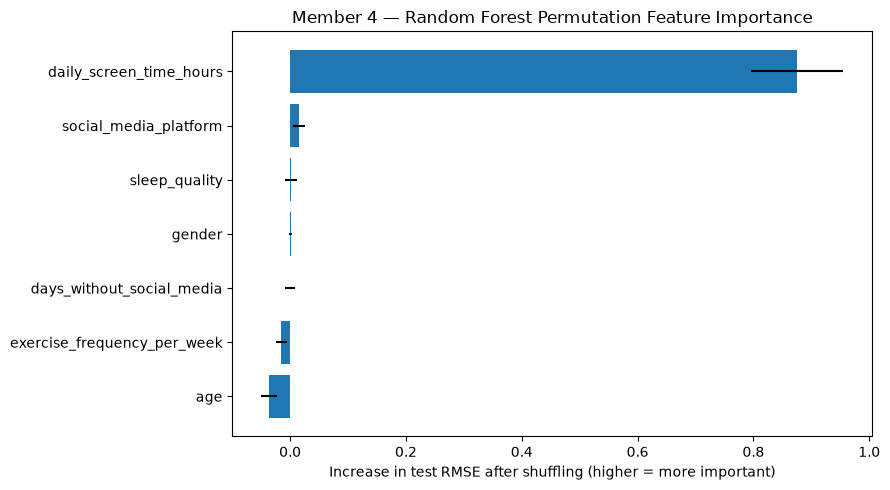

Most important predictor: daily_screen_time_hours


In [10]:
perm = permutation_importance(
    tuned_forest, X_test, y_test,
    scoring='neg_root_mean_squared_error', n_repeats=10,
    random_state=42, n_jobs=1
)
importance_df = pd.DataFrame({
    'Feature': features,
    'RMSE increase when shuffled': perm.importances_mean,
    'Std': perm.importances_std,
}).sort_values('RMSE increase when shuffled', ascending=False)
display(importance_df.round(4))
importance_df.to_csv(REPORT_DIR / 'member4_feature_importance.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 5))
plot_df = importance_df.sort_values('RMSE increase when shuffled')
ax.barh(plot_df['Feature'], plot_df['RMSE increase when shuffled'], xerr=plot_df['Std'])
ax.set_xlabel('Increase in test RMSE after shuffling (higher = more important)')
ax.set_title('Member 4 — Random Forest Permutation Feature Importance')
fig.tight_layout()
fig.savefig(FIG_DIR / 'member4_feature_importance.png', dpi=160)
plt.show()
print('Most important predictor:', importance_df.iloc[0]['Feature'])

## 8. Predicted vs actual stress scores

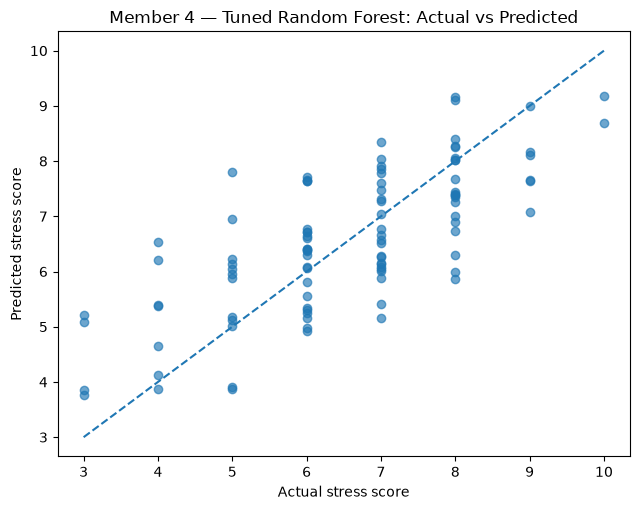

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
ax.scatter(y_test, tuned_pred, alpha=0.65)
axis_min = min(y_test.min(), tuned_pred.min())
axis_max = max(y_test.max(), tuned_pred.max())
ax.plot([axis_min, axis_max], [axis_min, axis_max], linestyle='--')
ax.set_xlabel('Actual stress score')
ax.set_ylabel('Predicted stress score')
ax.set_title('Member 4 — Tuned Random Forest: Actual vs Predicted')
fig.tight_layout()
fig.savefig(FIG_DIR / 'member4_actual_vs_predicted.png', dpi=160)
plt.show()

## 9. Stretch goal: predict happiness
Repeat the test with `happiness_index` as target using the **same habit/demographic predictors**, without using stress as an input. We fit on the happiness training subset and evaluate on the held-out 20%.

In [12]:
X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    df[features], df['happiness_index'], test_size=0.20, random_state=42
)
happy_linear = linear_model().fit(X_h_train, y_h_train)
happy_forest = forest_model().fit(X_h_train, y_h_train)
happiness_comparison = pd.DataFrame.from_dict({
    'Linear Regression': scores(y_h_test, happy_linear.predict(X_h_test)),
    'Random Forest': scores(y_h_test, happy_forest.predict(X_h_test)),
}, orient='index')
happiness_comparison.index.name = 'Model'
display(happiness_comparison.round(4))
happiness_comparison.to_csv(REPORT_DIR / 'member4_happiness_comparison.csv')

,RMSE,R2
Model,,
Linear Regression,1.0591,0.5278
Random Forest,1.1166,0.4752


## 10. Stretch goal: K-Means clustering
Cluster using behavior/demographic predictors only, excluding stress and happiness so that outcomes can be **compared after** segmentation. We scale numeric variables and one-hot encode categorical ones. Test k=3 and k=4 using silhouette score. A score near zero means groups overlap substantially.

Silhouette scores: {3: 0.1357, 4: 0.1338}
Chosen number of clusters: 3


,Users,daily_screen_time_hours,stress_level,sleep_quality,exercise_frequency_per_week,happiness_index,Segment Name
Cluster,,,,,,,
0,177,5.75,6.74,6.07,2.91,8.40,Middle Screen Time
1,163,6.99,7.65,5.06,2.02,7.25,Higher Screen Time
2,160,3.80,5.43,7.82,2.38,9.51,Lower Screen Time


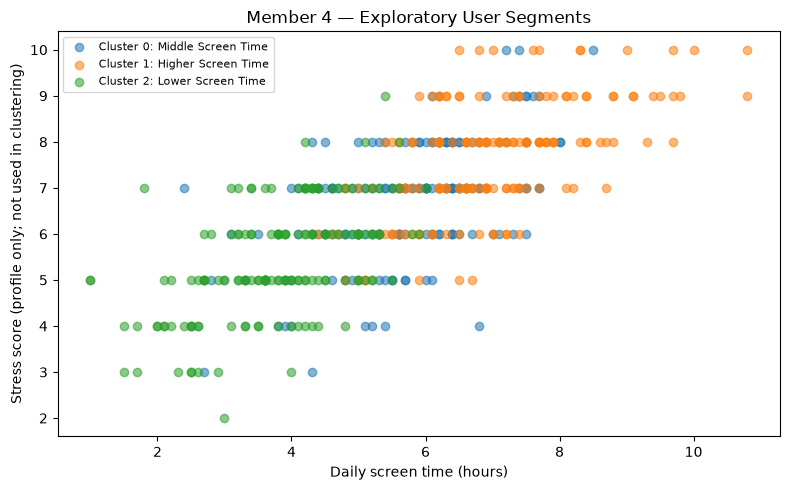

In [13]:
cluster_prep = preprocessing()
Z = cluster_prep.fit_transform(df[features])
# Convert sparse output if the preprocessor returns it.
if hasattr(Z, 'toarray'):
    Z = Z.toarray()
cluster_scores = {}
for k in [3, 4]:
    trial = KMeans(n_clusters=k, random_state=42, n_init=10)
    trial_labels = trial.fit_predict(Z)
    cluster_scores[k] = float(silhouette_score(Z, trial_labels))
print('Silhouette scores:', {k: round(v, 4) for k, v in cluster_scores.items()})
best_k = max(cluster_scores, key=cluster_scores.get)
print('Chosen number of clusters:', best_k)
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(Z)
clustered = df.copy()
clustered['Cluster'] = clusters
profile_columns = ['daily_screen_time_hours', 'stress_level', 'sleep_quality',
                   'exercise_frequency_per_week', 'happiness_index']
profiles = clustered.groupby('Cluster')[profile_columns].mean().round(2)
profiles.insert(0, 'Users', clustered.groupby('Cluster').size())
# Names describe observed screen time relative to the other segments.
sorted_ids = profiles['daily_screen_time_hours'].sort_values().index.tolist()
if best_k == 3:
    names = ['Lower Screen Time', 'Middle Screen Time', 'Higher Screen Time']
else:
    names = ['Lowest Screen Time', 'Lower-Middle Screen Time',
             'Upper-Middle Screen Time', 'Highest Screen Time']
name_map = dict(zip(sorted_ids, names))
profiles['Segment Name'] = profiles.index.map(name_map)
display(profiles)
profiles.to_csv(REPORT_DIR / 'member4_cluster_profiles.csv')
fig, ax = plt.subplots(figsize=(8, 5))
for c in sorted(clustered['Cluster'].unique()):
    portion = clustered[clustered['Cluster'] == c]
    ax.scatter(portion['daily_screen_time_hours'], portion['stress_level'],
               label=f'Cluster {c}: {name_map[c]}', alpha=0.55)
ax.set_xlabel('Daily screen time (hours)')
ax.set_ylabel('Stress score (profile only; not used in clustering)')
ax.set_title('Member 4 — Exploratory User Segments')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / 'member4_cluster_profiles.png', dpi=160)
plt.show()

## 11. Interpretation, limitations and automatically generated report
These results measure predictive associations. The sample is small (500 records), observational, and self-reported. Screen time, stress, and happiness can share underlying drivers. The held-out test results are subject to sampling uncertainty. K-Means cluster separation must be judged using the silhouette scores, not assumed.

In [14]:
best_name = comparison['RMSE'].idxmin()
top_feature = str(importance_df.iloc[0]['Feature'])
cluster_lines = '\n'.join(
    f"- Cluster {int(idx)} ({row['Segment Name']}): {int(row['Users'])} users, "
    f"{row['daily_screen_time_hours']:.2f} hours screen time, "
    f"stress {row['stress_level']:.2f}, sleep {row['sleep_quality']:.2f}, "
    f"exercise {row['exercise_frequency_per_week']:.2f}, "
    f"happiness {row['happiness_index']:.2f}."
    for idx, row in profiles.iterrows()
)
report = f"""# Member 4 — Regression Modeling and User Segmentation

## Objective and methods
We predicted numerical stress scores using age, gender, daily screen time, sleep quality,
days without social media, exercise frequency, and preferred social media platform.
We excluded the user ID, derived screen-time category, and happiness outcome.
The cleaned dataset contains {len(df)} observations. We used an 80/20 train/test split
(random_state=42), one-hot encoding, standardized numeric predictors, five-fold
cross-validation on training data, and GridSearchCV for Random Forest.

## Regression results (held-out test data)
{comparison.round(4).to_markdown()}

The lowest test RMSE was obtained by **{best_name}**. Lower RMSE and higher R²
indicate better predictive performance; test scores should not be interpreted as causation.

## Five-fold cross-validation (training set)
{cv_table[['CV mean RMSE', 'CV std RMSE']].round(4).to_markdown()}

## Tuned Random Forest
Best GridSearchCV parameters: `{search.best_params_}`. Best training-CV RMSE:
{-search.best_score_:.4f}.

## Feature importance
The highest test permutation-importance predictor was **{top_feature}**.
Permutation importance describes model reliance; it does not prove the predictor
causes changes in stress. The ranked details are in `member4_feature_importance.csv`.

## Happiness prediction (stretch)
{happiness_comparison.round(4).to_markdown()}

## User segmentation (stretch)
K-Means silhouette scores: {', '.join(f'k={k}: {v:.4f}' for k,v in cluster_scores.items())}.
We selected k={best_k} by the higher score of the tested options. Behavior/demographic
variables defined the clusters; stress and happiness were used only to profile them.
{cluster_lines}

These labels summarize relative averages, not distinct clinical categories. Low silhouette
scores indicate overlapping segments.

## Conclusions and recommendations
- Compare Linear Regression and tuned Random Forest using held-out RMSE and R².
- Screen time and other variables can help predict stress, but associations are not causal.
- Use user segments as exploratory descriptions, not definitive categories.
- To improve reliability, collect larger, more representative samples and validate externally.

## Limitations
1. Only 500 observations; the sample may not represent all users.
2. Self-reported lifestyle and wellbeing measurements may contain bias.
3. Unmeasured variables can affect stress; observational results do not prove causation.
4. Model scores can vary on other train/test samples, and clusters may overlap.

## Files exported
- `reports/member4_model_comparison.csv`
- `reports/member4_cross_validation.csv`
- `reports/member4_feature_importance.csv`
- `reports/member4_happiness_comparison.csv`
- `reports/member4_cluster_profiles.csv`
- `reports/figures/member4_feature_importance.png`
- `reports/figures/member4_actual_vs_predicted.png`
- `reports/figures/member4_cluster_profiles.png`

## References
- Scikit-learn documentation: https://scikit-learn.org/stable/
- Pandas documentation: https://pandas.pydata.org/docs/
- Dataset provenance: see the project's README and data dictionary for its original source.
"""
report_path = REPORT_DIR / 'part4_regression_summary.md'
report_path.write_text(report, encoding='utf-8')
print('REPORT SAVED:', report_path)
print('FIGURES SAVED:', *sorted(p.name for p in FIG_DIR.glob('member4_*.png')), sep='\n - ')
print('Done! All Member 4 analysis outputs have been saved.')

REPORT SAVED: C:\Users\Owner\Downloads\social-media-stress-analysis-main\social-media-stress-analysis-main\reports\part4_regression_summary.md
FIGURES SAVED:
 - member4_actual_vs_predicted.png
 - member4_cluster_profiles.png
 - member4_feature_importance.png
Done! All Member 4 analysis outputs have been saved.
